## Implementation of Linear regression using python

In [3]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt


## Load the dataset

In [2]:
DF1 = pd.read_csv('weight-height - weight-height.csv')
DF1.sample(10)

,Gender,Height,Weight
6285,Female,64.991714,137.801970
1414,Male,67.405755,163.476510
6990,Female,63.491269,123.186629
8352,Female,62.564346,123.554176
6968,Female,63.504695,123.504328
3558,Male,64.784733,173.900511
1570,Male,65.924741,152.949488
5212,Female,63.218759,140.407858
1119,Male,70.857932,187.105364
4838,Male,68.502943,195.045319


### Standardize numerical features

In [3]:
col = ["Height" , "Weight"]
S1 = MinMaxScaler()
DF1[col] = S1.fit_transform(DF1[col])
DF1.sample(10)

,Gender,Height,Weight
503,Male,0.139524,0.626887
6836,Female,0.070669,0.244156
3453,Male,0.122443,0.548768
4988,Male,0.141587,0.616565
559,Male,0.088277,0.509075
327,Male,0.128361,0.632782
7558,Female,0.061259,0.293820
7321,Female,0.122061,0.484243
4679,Male,0.122089,0.571168
7177,Female,0.077729,0.305113


## Prepare dependant and independant variables

In [4]:
x = DF1[["Height"]].to_numpy()
y = DF1[["Weight"]].to_numpy()
x.shape


(10000, 1)

In [5]:
#we have to use the height as an independent variable and use it predict the weight of the person 

## Split the data into training and test set

In [6]:
X_train,X_test,Y_train,Y_test=train_test_split(x,y,test_size=.2,random_state=67)

In [7]:
# Create a linear regression model

model=LinearRegression()


Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [8]:
## Training  Linear regressions model 

In [9]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [10]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.004438047889011704
0.06661867522708406
0.054480150433493836
0.8135299373473699
[3.54709605]
[0.10829265]


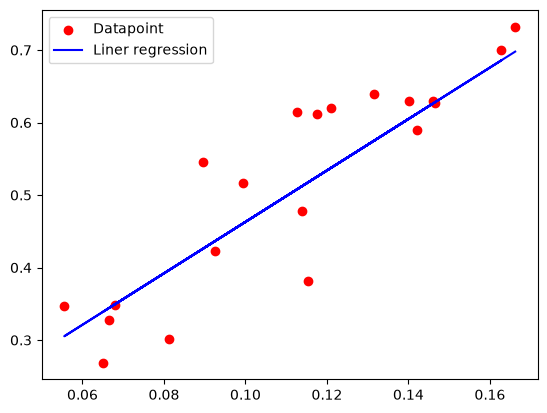

In [11]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()


In [12]:
## Load the Height and weight  to indipendent and dependent variable 

In [13]:
df2=pd.read_csv("weight-height - weight-height.csv")
x = df2[["Height"]].values.reshape(-1, 1)
x.shape
y=df2["Weight"].values
print(x.shape)
print(y.shape)

(10000, 1)
(10000,)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [14]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (x - np.mean(x, axis=0)) / np.std(x, axis=0)
Y = (y - np.mean(y, axis=0)) / np.std(y, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [15]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))

In [16]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=1000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[]
print(X.shape)
m=X.T
print(m.shape)

(10000, 2)
(2, 10000)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

In [17]:
for i in range(iterations):
    y_pred = np.dot(X, theta)
    mse=mean_squared_error(Y, y_pred)
    mseh.append(mse)
    print(f"Iteration {i+1}: MSE = {mse}")
    gradient = np.dot(X.T, (y_pred - Y)) / Y.size
    theta -= learningrate * gradient

Iteration 1: MSE = 1.0
Iteration 2: MSE = 0.985809419277575
Iteration 3: MSE = 0.9719012311115264
Iteration 4: MSE = 0.9582698158899818
Iteration 5: MSE = 0.9449096658313463
Iteration 6: MSE = 0.9318153827588774
Iteration 7: MSE = 0.9189816759195508
Iteration 8: MSE = 0.9064033598463267
Iteration 9: MSE = 0.8940753522629599
Iteration 10: MSE = 0.8819926720305018
Iteration 11: MSE = 0.87015043713467
Iteration 12: MSE = 0.8585438627132649
Iteration 13: MSE = 0.847168259122846
Iteration 14: MSE = 0.8360190300438766
Iteration 15: MSE = 0.8250916706235781
Iteration 16: MSE = 0.8143817656557442
Iteration 17: MSE = 0.8038849877967698
Iteration 18: MSE = 0.7935970958171891
Iteration 19: MSE = 0.7835139328880019
Iteration 20: MSE = 0.7736314249011057
Iteration 21: MSE = 0.7639455788231487
Iteration 22: MSE = 0.7544524810821431
Iteration 23: MSE = 0.7451482959861835
Iteration 24: MSE = 0.7360292641736333
Iteration 25: MSE = 0.727091701094153
Iteration 26: MSE = 0.7183319955199544
Iteration 27: M

Iteration 142: MSE = 0.32881108220485583
Iteration 143: MSE = 0.32797716094655427
Iteration 144: MSE = 0.32715983472129284
Iteration 145: MSE = 0.32635877328791413
Iteration 146: MSE = 0.32557365297705965
Iteration 147: MSE = 0.32480415656039113
Iteration 148: MSE = 0.3240499731224144
Iteration 149: MSE = 0.32331079793485334
Iteration 150: MSE = 0.3225863323335248
Iteration 151: MSE = 0.3218762835976626
Iteration 152: MSE = 0.3211803648316442
Iteration 153: MSE = 0.3204982948490695
Iteration 154: MSE = 0.319829798059148
Iteration 155: MSE = 0.319174604355346
Iteration 156: MSE = 0.31853244900624966
Iteration 157: MSE = 0.3179030725486003
Iteration 158: MSE = 0.31728622068245815
Iteration 159: MSE = 0.3166816441684522
Iteration 160: MSE = 0.316089098727075
Iteration 161: MSE = 0.31550834493998126
Iteration 162: MSE = 0.3149391481532506
Iteration 163: MSE = 0.31438127838257596
Iteration 164: MSE = 0.3138345102203377
Iteration 165: MSE = 0.31329862274452797
Iteration 166: MSE = 0.31277339

Iteration 689: MSE = 0.28690619469087986
Iteration 690: MSE = 0.2869061806941064
Iteration 691: MSE = 0.2869061669758687
Iteration 692: MSE = 0.2869061535306239
Iteration 693: MSE = 0.28690614035293954
Iteration 694: MSE = 0.286906127437491
Iteration 695: MSE = 0.28690611477906
Iteration 696: MSE = 0.28690610237253167
Iteration 697: MSE = 0.28690609021289326
Iteration 698: MSE = 0.2869060782952318
Iteration 699: MSE = 0.28690606661473167
Iteration 700: MSE = 0.28690605516667345
Iteration 701: MSE = 0.2869060439464317
Iteration 702: MSE = 0.28690603294947276
Iteration 703: MSE = 0.2869060221713532
Iteration 704: MSE = 0.2869060116077183
Iteration 705: MSE = 0.2869060012542997
Iteration 706: MSE = 0.28690599110691417
Iteration 707: MSE = 0.28690598116146154
Iteration 708: MSE = 0.28690597141392354
Iteration 709: MSE = 0.28690596186036144
Iteration 710: MSE = 0.2869059524969153
Iteration 711: MSE = 0.2869059433198017
Iteration 712: MSE = 0.28690593432531264
Iteration 713: MSE = 0.28690592

Iteration 723: MSE = 0.2869058464496703
Iteration 724: MSE = 0.28690583938289693
Iteration 725: MSE = 0.2869058324567523
Iteration 726: MSE = 0.2869058256684379
Iteration 727: MSE = 0.286905819015211
Iteration 728: MSE = 0.28690581249438335
Iteration 729: MSE = 0.28690580610332006
Iteration 730: MSE = 0.2869057998394391
Iteration 731: MSE = 0.28690579370020924
Iteration 732: MSE = 0.28690578768315006
Iteration 733: MSE = 0.2869057817858304
Iteration 734: MSE = 0.28690577600586736


Iteration 735: MSE = 0.2869057703409256
Iteration 736: MSE = 0.2869057647887162
Iteration 737: MSE = 0.28690575934699575
Iteration 738: MSE = 0.2869057540135656
Iteration 739: MSE = 0.2869057487862706
Iteration 740: MSE = 0.2869057436629988
Iteration 741: MSE = 0.28690573864168023
Iteration 742: MSE = 0.28690573372028577
Iteration 743: MSE = 0.2869057288968271
Iteration 744: MSE = 0.2869057241693552
Iteration 745: MSE = 0.2869057195359601
Iteration 746: MSE = 0.28690571499476947
Iteration 747: MSE = 0.2869057105439486
Iteration 748: MSE = 0.286905706181699
Iteration 749: MSE = 0.2869057019062582
Iteration 750: MSE = 0.2869056977158987
Iteration 751: MSE = 0.2869056936089273
Iteration 752: MSE = 0.2869056895836847
Iteration 753: MSE = 0.28690568563854435
Iteration 754: MSE = 0.2869056817719123
Iteration 755: MSE = 0.2869056779822263
Iteration 756: MSE = 0.286905674267955
Iteration 757: MSE = 0.28690567062759775
Iteration 758: MSE = 0.2869056670596835
Iteration 759: MSE = 0.2869056635627

Iteration 893: MSE = 0.28690550298565115
Iteration 894: MSE = 0.28690550275381177
Iteration 895: MSE = 0.28690550252658586
Iteration 896: MSE = 0.2869055023038818
Iteration 897: MSE = 0.28690550208560955
Iteration 898: MSE = 0.2869055018716809
Iteration 899: MSE = 0.28690550166200957
Iteration 900: MSE = 0.2869055014565106
Iteration 901: MSE = 0.286905501255101
Iteration 902: MSE = 0.2869055010576995
Iteration 903: MSE = 0.2869055008642263
Iteration 904: MSE = 0.2869055006746032
Iteration 905: MSE = 0.2869055004887536
Iteration 906: MSE = 0.28690550030660245
Iteration 907: MSE = 0.2869055001280761
Iteration 908: MSE = 0.28690549995310227
Iteration 909: MSE = 0.2869054997816106
Iteration 910: MSE = 0.2869054996135315
Iteration 911: MSE = 0.2869054994487973
Iteration 912: MSE = 0.28690549928734127
Iteration 913: MSE = 0.2869054991290982
Iteration 914: MSE = 0.28690549897400414
Iteration 915: MSE = 0.2869054988219965
Iteration 916: MSE = 0.2869054986730137
Iteration 917: MSE = 0.286905498

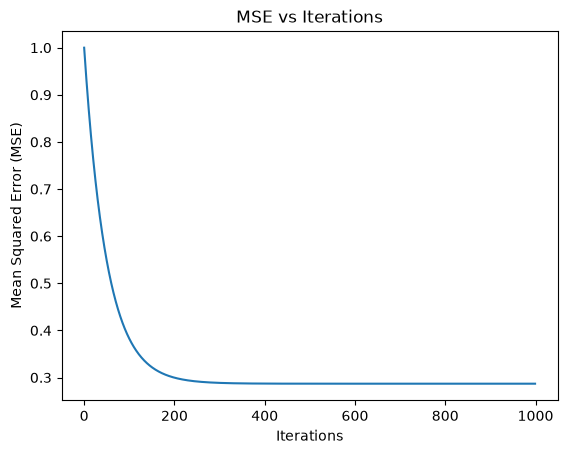

In [18]:
# Plot the MSE over iterations
plt.plot(range(iterations), mseh)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE vs Iterations')
plt.show()

## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

In [4]:
df3 = pd.read_csv('Food_Delivery_Times - Food_Delivery_Times.csv')
df3.sample(10)

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
728,203,3.65,Clear,Medium,Morning,Bike,29,9.0,46
867,139,7.59,Clear,NaN,Afternoon,Scooter,16,3.0,37
258,923,17.94,Rainy,High,Evening,Scooter,22,6.0,85
184,846,8.59,Clear,Low,Evening,Bike,22,2.0,43
40,329,8.68,Rainy,Medium,Morning,Bike,8,5.0,52
597,603,3.95,Clear,Medium,Morning,Car,28,5.0,47
610,181,7.15,Windy,Low,Morning,Bike,15,3.0,42
308,935,3.85,Rainy,Medium,Afternoon,Bike,26,3.0,46
135,56,18.48,Clear,Medium,Night,Bike,8,0.0,82
723,280,16.02,Clear,Low,Evening,Bike,20,7.0,61


In [5]:
df3 = df3[['Distance_km', 'Preparation_Time_min', 'Weather', 'Traffic_Level', 'Delivery_Time_min']].dropna()
df3.sample(5)

,Distance_km,Preparation_Time_min,Weather,Traffic_Level,Delivery_Time_min
697,4.71,20,Clear,Low,31
148,7.00,17,Rainy,Medium,49
975,12.59,10,Clear,Low,39
727,17.61,5,Windy,Low,61
50,10.52,8,Rainy,Medium,56


In [6]:
df3 = pd.get_dummies(df3, columns=['Weather', 'Traffic_Level'], dtype=int)
df3.sample(5)

,Distance_km,Preparation_Time_min,Delivery_Time_min,Weather_Clear,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy,Traffic_Level_High,Traffic_Level_Low,Traffic_Level_Medium
708,18.80,23,95,1,0,0,0,0,1,0,0
529,11.44,20,57,0,0,1,0,0,0,0,1
321,1.50,15,32,0,1,0,0,0,0,0,1
73,6.38,16,111,0,0,0,1,0,0,1,0
121,11.22,25,79,0,0,0,0,1,1,0,0


In [7]:
X = df3.drop(columns=['Delivery_Time_min']).to_numpy()
y = df3[['Delivery_Time_min']].to_numpy()
print(X.shape)
print(y.shape)

(940, 10)
(940, 1)


In [8]:
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=.2, random_state=67)

In [9]:
model = LinearRegression()
model.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 10)","[[ 3.02, 1.02,-5.67,..., 5.79,-5.64,-0.15]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[12.2]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[199.21,154.74, 17.4 ,..., 8.52, 0. , 0. ]"


In [10]:
Y_pred = model.predict(X_test)
mse = mean_squared_error(Y_test, Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

103.18196840004218
10.157852548646401
6.4887159100030685
0.7685595448943009


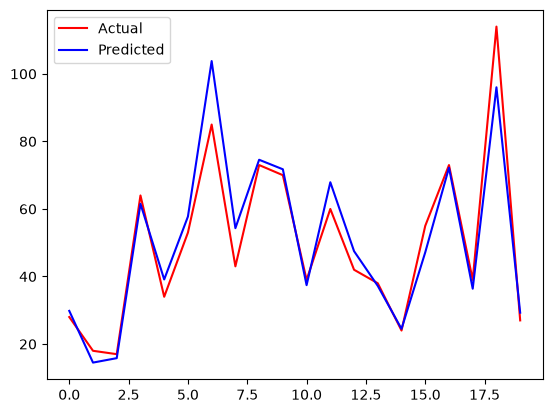

In [11]:
plt.plot(Y_test[0:20], color="Red", label="Actual")
plt.plot(Y_pred[0:20], color="Blue", label="Predicted")
plt.legend()